#### PpIA: Actividad fundamental 3

#### ejercicio de árbol de decisión
Equipo:

Cristofer Jair Zuñiga Escobar 2189229

Leonardo Alfredo López Reyes 2181755

Diego Otoniel Cantu Cantu 2208782

Angel Gabriel Alonso Navarro 2116170

Alexis Eduardo Puente Mendoza 2188873



### Entrenamiento de árbol de decisión: Predicción de Diabetes con Preprocesamiento Avanzado

Se importan las librerías Pandas, NumPy, Matplotlib y Scikit-Learn, necesarias para el análisis, procesamiento y modelado de los datos.
Posteriormente, se carga un conjunto de datos público sobre diabetes que contiene 768 registros y nueve columnas, incluyendo las características de los pacientes y su diagnóstico.

In [1]:
#Importacion de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columnas = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

df = pd.read_csv(url, header=None, names=columnas)

### 2. Análisis exploratorio de datos

Se utilizan las funciones `head()`, `describe()`, `info()` e `isnull().sum()` para conocer la estructura del conjunto de datos, sus estadísticas descriptivas y la presencia de valores faltantes.

Además, se genera un diagrama de dispersión que relaciona la glucosa con el índice de masa corporal (BMI), diferenciando mediante colores a los pacientes con y sin diabetes.

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   

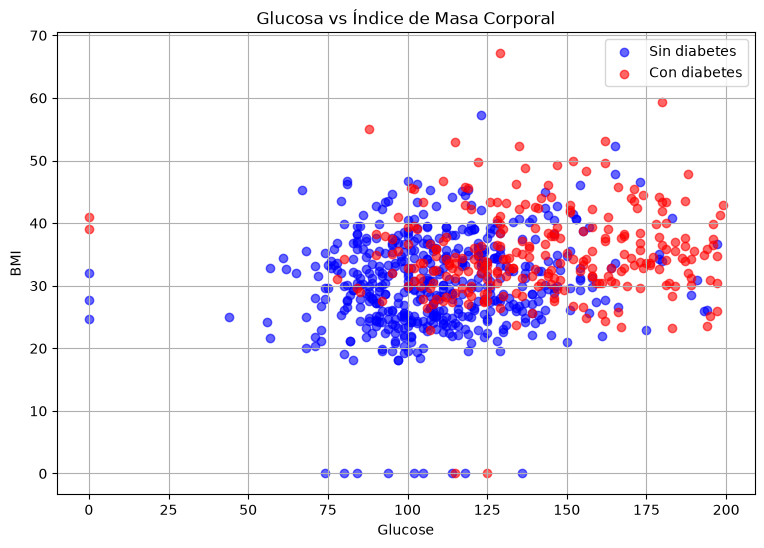

In [2]:
#Analisis exploratorio de datos
# Información general del dataset
print(df.head())
print(df.describe())
df.info()
print(df.isnull().sum())
# Separación de pacientes según su diagnóstico
sin_diabetes = df[df["Outcome"] == 0]
con_diabetes = df[df["Outcome"] == 1]

# Gráfica de dispersión
plt.figure(figsize=(9, 6))

plt.scatter(
    sin_diabetes["Glucose"],
    sin_diabetes["BMI"],
    color="blue",
    label="Sin diabetes",
    alpha=0.6
)

plt.scatter(
    con_diabetes["Glucose"],
    con_diabetes["BMI"],
    color="red",
    label="Con diabetes",
    alpha=0.6
)

plt.title("Glucosa vs Índice de Masa Corporal")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.legend()
plt.grid()
plt.show()

### 3. Preparación inicial de datos

Se separan las variables independientes (`X`) de la variable objetivo (`y`), correspondiente al diagnóstico de diabetes.

Posteriormente, los datos se dividen en un 75 % para entrenamiento y un 25 % para prueba, utilizando `random_state=42` para garantizar resultados reproducibles y `stratify=y` para conservar la proporción de ambas clases.

In [3]:
# Preparación inicial de datos
# Separar características y resultados
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

# Dividir los datos originales
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))


Registros de entrenamiento: 576
Registros de prueba: 192


### 4. Limpieza de datos

Se identifican los valores de cero que representan datos inválidos en las columnas Glucose, BloodPressure, SkinThickness, Insulin y BMI, reemplazándolos por valores nulos (`NaN`).

Después, se calcula la mediana de cada columna utilizando únicamente los datos de entrenamiento y se aplica a ambos conjuntos para completar los valores faltantes, evitando utilizar información de prueba durante el preprocesamiento.

In [4]:
# 4. Limpieza de datos
columnas_limpiar = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Crear copias de los conjuntos
X_train = X_train.copy()
X_test = X_test.copy()

for columna in columnas_limpiar:

    # Convertir ceros inválidos en valores faltantes
    X_train[columna] = X_train[columna].replace(0, np.nan)
    X_test[columna] = X_test[columna].replace(0, np.nan)

    # Calcular la mediana usando solo entrenamiento
    mediana = X_train[columna].median()

    # Aplicar la misma mediana a ambos conjuntos
    X_train[columna] = X_train[columna].fillna(mediana)
    X_test[columna] = X_test[columna].fillna(mediana)

print("Valores faltantes en entrenamiento:")
print(X_train.isnull().sum())

print("\nValores faltantes en prueba:")
print(X_test.isnull().sum())

Valores faltantes en entrenamiento:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64

Valores faltantes en prueba:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


### 5. Detección y eliminación de valores atípicos (IQR)

Se utiliza el rango intercuartílico (IQR) para identificar valores atípicos en la columna Insulin, calculando los cuartiles Q1 y Q3 mediante NumPy y estableciendo límites de 1.5 veces el IQR.

Se eliminan 17 registros atípicos del conjunto de entrenamiento, conservando 559 registros para el modelado y los 192 registros originales de prueba.

In [5]:
# 5. Detección y eliminación de outliers

# Recuperar los valores originales de insulina del entrenamiento
insulina_original = df.loc[X_train.index, "Insulin"]

# Excluir ceros inválidos
insulina_valida = insulina_original[insulina_original > 0]

# Calcular cuartiles e IQR
Q1 = np.percentile(insulina_valida, 25)
Q3 = np.percentile(insulina_valida, 75)

IQR = Q3 - Q1

# Calcular límites
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Identificar registros válidos
filtro = (
    (X_train["Insulin"] >= limite_inferior) &
    (X_train["Insulin"] <= limite_superior)
)

registros_antes = len(X_train)

# Eliminar outliers solo del entrenamiento
X_train = X_train.loc[filtro].copy()
y_train = y_train.loc[filtro].copy()

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)
print("Registros eliminados:", registros_antes - len(X_train))
print("Registros de entrenamiento restantes:", len(X_train))
print("Registros de prueba:", len(X_test))

Q1: 76.0
Q3: 181.0
IQR: 105.0
Límite inferior: -81.5
Límite superior: 338.5
Registros eliminados: 17
Registros de entrenamiento restantes: 559
Registros de prueba: 192


### 6. Entrenamiento y evaluación de árboles de decisión

Se entrenan tres modelos de árbol de decisión: uno original sin restricciones, uno ajustado con profundidad máxima de tres niveles y uno balanceado que considera las diferencias en la cantidad de pacientes de cada clase.

Se evalúan mediante la exactitud (accuracy), precisión, recall y F1-score. El modelo balanceado obtuvo una exactitud del 72.40 % y un recall del 75 % para pacientes con diabetes, presentando los mejores resultados de esta comparación para identificar casos positivos.

In [6]:
#Entrenamiento y comparacion de modelos
modelos = {
    "Original": DecisionTreeClassifier(
        random_state=42
    ),

    "Ajustado": DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ),

    "Balanceado": DecisionTreeClassifier(
        max_depth=3,
        class_weight="balanced",
        random_state=42
    )
}

for nombre, modelo in modelos.items():

    modelo.fit(X_train, y_train)

    y_pred = modelo.predict(X_test)

    print("\nModelo:", nombre)

    print(
        "Accuracy entrenamiento:",
        modelo.score(X_train, y_train)
    )

    print(
        "Accuracy prueba:",
        accuracy_score(y_test, y_pred)
    )

    print(classification_report(y_test, y_pred))



Modelo: Original
Accuracy entrenamiento: 1.0
Accuracy prueba: 0.7135416666666666
              precision    recall  f1-score   support

           0       0.77      0.79      0.78       125
           1       0.59      0.57      0.58        67

    accuracy                           0.71       192
   macro avg       0.68      0.68      0.68       192
weighted avg       0.71      0.71      0.71       192


Modelo: Ajustado
Accuracy entrenamiento: 0.7710196779964222
Accuracy prueba: 0.703125
              precision    recall  f1-score   support

           0       0.71      0.93      0.80       125
           1       0.68      0.28      0.40        67

    accuracy                           0.70       192
   macro avg       0.69      0.61      0.60       192
weighted avg       0.70      0.70      0.66       192


Modelo: Balanceado
Accuracy entrenamiento: 0.7656529516994633
Accuracy prueba: 0.7239583333333334
              precision    recall  f1-score   support

           0       0.84

### 7. Visualización del árbol de decisión

Se utiliza `plot_tree()` de Scikit-Learn junto con Matplotlib para representar gráficamente la estructura del modelo balanceado.

La visualización permite identificar las variables y condiciones utilizadas para clasificar a los pacientes, así como observar las decisiones que conducen a una predicción de diabetes o ausencia de ella.

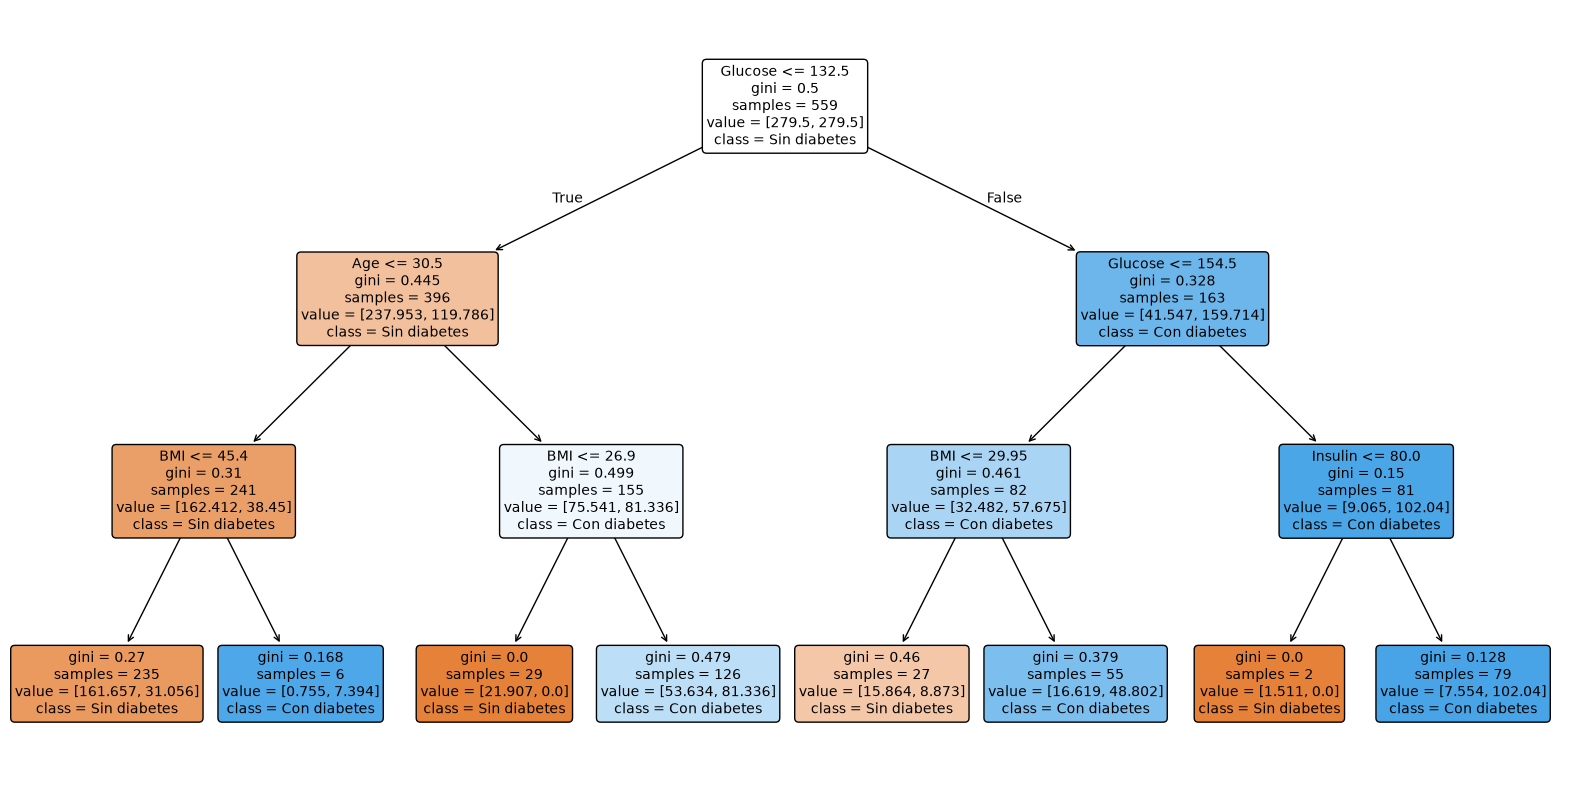

In [7]:
# 7. Visualización del árbol de decisión

modelo_visualizar = modelos["Balanceado"]

plt.figure(figsize=(16, 8))

plot_tree(
    modelo_visualizar,
    feature_names=X.columns,
    class_names=["Sin diabetes", "Con diabetes"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.tight_layout()
plt.show()